Fine-tuning a pretrained transformer BERT model for customized sentiment analysis using transformer PyTorch Trainer from Hugging Face

# Intro

Hugging Face provides three ways to fine-tune a pretrained text classification model: Tensorflow Keras, PyTorch, and transformer trainer. Transformer trainer is an API for feature-complete training in PyTorch without writing all the loops. This assignment will use the transformer trainer to fine-tune a text classification model. We will talk about the following:
* How does transfer learning work?
* How to convert a pandas dataframe into a Hugging Face Dataset?
* How to tokenize text, load a pretrained model, set training arguments, and train a transfer learning model?
* How to make predictions and evaluate the model performance of a fine-tuned transfer learning model for text classification?
* How to save the model and re-load the model?

Let's get started!

# Step 0: Transfer Learning Algorithms

In step 0, we will talk about how transfer learning works.

Transfer learning is a machine learning technique that reuses a pretrained large deep learning model on a new task. It usually includes the following steps:
1. Select a pretrained model that is suitable for the new task. For example, if the new task includes text from different languages, a multi-language pretrained model needs to be selected.
2. Keep all the weights and biases from the pretrained model except for the output layer. This is because the output layer for the pretrained model is for the pretrained tasks and it needs to be replaced with the new task.
3. Feed randomly initialize weights and biases into the new head of the new task. For a sentiment analysis transfer learning (aka fine-tuning) model on a pretrained BERT model, we will remove the head that classifies mask words, and replace it with the two sentiment analysis labels, positive and negative.
4. Retrain the model for the new task with the new data, utilizing the pretrained weights and biases. Because the weights and biases store the knowledge learned from the pretrained model, the fine-tuned transfer learning model can build on that knowledge and does not need to learn from scratch.

# Step 1: Install And Import Python Libraries

In step 1, we will install and import python libraries.

Firstly, let's install `transformers`, `datasets`, and `evaluate`.

In [1]:
# Install libraries
!pip install transformers datasets evaluate


# This line installs the main libraries required for the project:
    # transformers: used for working with pretrained models such as BERT
    # datasets: used for loading and managing data in the standard Hugging Face Dataset format
    # evaluate: used for computing metrics such as accuracy, precision, F1, and others

After installing the python packages, we will import the python libraries.
* `pandas` and `numpy` are imported for data processing.
* `tensorflow` and `transformers` are imported for modeling.
* `Dataset` is imported for the Hugging Face dataset format.
* `evaluate` is imported for model performance evaluation.

In [2]:
# Data processing
import pandas as pd
import numpy as np

# Modeling
import tensorflow as tf
from transformers import AutoTokenizer, AutoModelForSequenceClassification, \
    TrainingArguments, Trainer, EarlyStoppingCallback, TextClassificationPipeline

from transformers import AutoTokenizer

# Hugging Face Dataset
from datasets import Dataset

# Model performance evaluation
import evaluate

c:\Users\niush\anaconda3\lib\site-packages\numpy\_distributor_init.py:30: UserWarning: loaded more than 1 DLL from .libs:
c:\Users\niush\anaconda3\lib\site-packages\numpy\.libs\libopenblas.XWYDX2IKJW2NMTWSFYNGFUWKQU3LYTCZ.gfortran-win_amd64.dll
c:\Users\niush\anaconda3\lib\site-packages\numpy\.libs\libopenblas64__v0.3.21-gcc_10_3_0.dll
  warnings.warn("loaded more than 1 DLL from .libs:"
C:\Users\niush\AppData\Roaming\Python\Python310\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


# Step 2: Download And Read Data

The second step is to download and read the dataset.

The UCI Machine Learning Repository has the review data from three websites: imdb.com, amazon.com, and yelp.com. We will use the review data from amazon.com for this exercise. Please follow these steps to download the data.
1. Go to: https://archive.ics.uci.edu/ml/datasets/Sentiment+Labelled+Sentences
2. Click "Data Folder"
3. Download "sentiment labeled sentences.zip"
4. Unzip "sentiment labeled sentences.zip"
5. Copy the file "amazon_cells_labelled.txt" to your project folder

Those who are using Google Colab for this analysis need to mount Google Drive to read the dataset. You can ignore the code below if you are not using Google Colab.
* `drive.mount` is used to mount to the Google drive so the colab notebook can access the data on the Google drive.
* `os.chdir` is used to change the default directory on Google drive. I set the default directory to the folder where the review dataset is saved.
* `!pwd` is used to print the current working directory.

Please check out [Google Colab Tutorial for Beginners](https://medium.com/towards-artificial-intelligence/google-colab-tutorial-for-beginners-834595494d44) for details about using Google Colab for data science projects.

In [3]:
# # Mount Google Drive
# from google.colab import drive
# drive.mount('/content/drive')

# # Change directory
# import os
# os.chdir("path of dataset file")

# # Print out the current directory
# !pwd

Now let's read the data into a `pandas` dataframe and see what the dataset looks like.

The dataset has two columns. One column contains the reviews and the other column contains the sentiment label for the review.

In [4]:
# Read in data
amz_review = pd.read_csv('amazon_cells_labelled.txt', sep='\t', names=['review', 'label'])

# Take a look at the data
amz_review.head()

,review,label
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


`.info` helps us to get information about the dataset.

From the output, we can see that this data set has 1000 records and no missing data. The `review` column is the `object` type and the `label` column is the `int64` type.

In [5]:
# Get the dataset information
amz_review.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   review  1000 non-null   object
 1   label   1000 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 15.8+ KB


The label value of 0 represents negative reviews and the label value of 1 represents positive reviews. The dataset has 500 positive reviews and 500 negative reviews. It is well-balanced, so we can use  accuracy as the metric to evaluate the model performance.

In [6]:
amz_review

,review,label
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1
...,...,...
995,The screen does get smudged easily because it ...,0
996,What a piece of junk.. I lose more calls on th...,0
997,Item Does Not Match Picture.,0
998,The only thing that disappoint me is the infra...,0


In [7]:
# Check the label distribution
amz_review['label'].value_counts()

label
0    500
1    500
Name: count, dtype: int64

# Step 3: Train Test Split

In step 3, we will split the dataset and have 80% as the training dataset and 20% as the testing dataset.

Using the `sample` method, we set `frac=0.8`, which randomly samples 80% of the data. `random_state=42` ensures that the sampling result is reproducible.

Dropping the `train_data` from the review dataset gives us the rest 20% of the data, which is our testing dataset.

In [8]:
# Training dataset
train_data = amz_review.sample(frac=0.8, random_state=42)

# Testing dataset
test_data = amz_review.drop(train_data.index)

# Check the number of records in training and testing dataset.
print(f'The training dataset has {len(train_data)} records.')
print(f'The testing dataset has {len(test_data)} records.')

The training dataset has 800 records.
The testing dataset has 200 records.


After the train test split, there are 800 reviews in the training dataset and 200 reviews in the testing dataset.

# Step 4: Convert Pandas Dataframe to Hugging Face Dataset

In step 4, the training and the testing datasets will be converted from pandas dataframe to Hugging Face Dataset format.

Hugging Face Dataset objects are memory-mapped on drive, so they are not limited by RAM memory, which is very helpful for processing large datasets.

We use `Dataset.from_pandas` to convert a pandas dataframe to a Hugging Face Dataset.

In [9]:
# Convert pyhton dataframe to Hugging Face arrow dataset

hg_train_data = Dataset.from_pandas(train_data)
hg_test_data = Dataset.from_pandas(test_data)

The length of the Hugging Face Dataset is the same as the number of records in the pandas dataframe. For example, there are 800 records in the pandas dataframe for the training dataset, and the length of the converted Hugging Face Dataset for the training dataset is 800 too.

`hg_train_data[0]` gives us the first record in the Hugging Face Dataset. It is a dictionary with three keys, `review`, `label`, and `__index_level_0__`.
* `review` is the variable name for the review text. The name is inherited from the column name of the pandas dataframe.
* `label` is the variable name for the sentiment of the review text. The name is inherited from the column name of the pandas dataframe too.
* `__index_level_0__` is an automatically generated field from the pandas dataframe. It stores the index of the corresponding record.

In [10]:
# Length of the Dataset
print(f'The length of hg_train_data is {len(hg_train_data)}.\n')

# Check one review
hg_train_data[0]

The length of hg_train_data is 800.



{'review': 'Thanks again to Amazon for having the things I need for a good price!',
 'label': 1,
 '__index_level_0__': 521}

In this example, we can see that the review is `Thanks again to Amazon for having the things I need for a good price!`, the sentiment for the review is positive/1, and the index of this record is 521 in the pandas dataframe.

Checking the index 521 in the pandas dataframe confirms the same information with Hugging Face Dataset.

In [11]:
# Validate the record in pandas dataframe
amz_review.iloc[[521]]

,review,label
521,Thanks again to Amazon for having the things I...,1


# Step 5: Tokenize Text

In step 5, we will tokenize the review text using a tokenizer.

A tokenizer converts text into numbers to use as the input of the NLP (Natural Language Processing) models. Each number represents a token, which can be a word, part of a word, punctuation, or special tokens. How the text is tokenized is determined by the pretrained model. `AutoTokenizer.from_pretrained("bert-base-cased")` is used to download vocabulary from the pretrained `bert-base-cased` model, meaning that the text will be tokenized like a BERT model.

tokenizer("This is great!")

{
    
    'input_ids': [101, 1188, 1110, 1581, 106],  # لیستی از توکن‌ها 

    'token_type_ids': [0, 0, 0, 0, 0],
    
    'attention_mask': [1, 1, 1, 1, 1]
}

In [12]:
# Tokenizer from a pretrained model
tokenizer = AutoTokenizer.from_pretrained("bert-base-cased")

# Take a look at the tokenizer
tokenizer

c:\Users\niush\anaconda3\lib\site-packages\huggingface_hub\file_download.py:896: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


PreTrainedTokenizerFast(name_or_path='bert-base-cased', vocab_size=28996, model_max_len=512, is_fast=True, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'})

In [13]:
# Mapping between special tokens and their IDs.
print(f'The unknown token is {tokenizer.unk_token} and the ID for the unkown token is {tokenizer.unk_token_id}.')
print(f'The seperator token is {tokenizer.sep_token} and the ID for the seperator token is {tokenizer.sep_token_id}.')
print(f'The pad token is {tokenizer.pad_token} and the ID for the pad token is {tokenizer.pad_token_id}.')
print(f'The sentence level classification token is {tokenizer.cls_token} and the ID for the classification token is {tokenizer.cls_token_id}.')
print(f'The mask token is {tokenizer.mask_token} and the ID for the mask token is {tokenizer.mask_token_id}.')

The unknown token is [UNK] and the ID for the unkown token is 100.
The seperator token is [SEP] and the ID for the seperator token is 102.
The pad token is [PAD] and the ID for the pad token is 0.
The sentence level classification token is [CLS] and the ID for the classification token is 101.
The mask token is [MASK] and the ID for the mask token is 103.


We can see that the tokenizer contains information such as model name, vocabulary size, max length, padding position, truncation position, and special tokens.

There are five special tokens for the BERT model. Other models may have different special tokens.
 * The tokens that are not part of the BERT model training dataset are unknown tokens. The unknown token is [UNK] and the ID for the unknown token is 100.
 * The separator token is [SEP] and the ID for the separator token is 102.
 * The pad token is [PAD] and the ID for the pad token is 0.
 * The sentence level classification token is [CLS] and the ID for the classification token is 101.
 * The mask token is [MASK] and the ID for the mask token is 103.

In [14]:
# Get the first sentence from the dataset
sample_text = amz_review["review"].iloc[0]

# Apply the tokenizer to the sentence
tokenized_output = tokenizer(sample_text)

# Display the original text
print("Original Text:", sample_text)
print("\nTokenized Output:")

# Print each part of the tokenizer output on a separate line
for key, value in tokenized_output.items():
    print(f"{key}: {value}")

Original Text: So there is no way for me to plug it in here in the US unless I go by a converter.

Tokenized Output:
input_ids: [101, 1573, 1175, 1110, 1185, 1236, 1111, 1143, 1106, 15244, 1122, 1107, 1303, 1107, 1103, 1646, 4895, 146, 1301, 1118, 170, 10454, 1200, 119, 102]
token_type_ids: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [15]:
print("\nDecoded Tokens:")
print(tokenizer.convert_ids_to_tokens(tokenized_output["input_ids"]))


Decoded Tokens:
['[CLS]', 'So', 'there', 'is', 'no', 'way', 'for', 'me', 'to', 'plug', 'it', 'in', 'here', 'in', 'the', 'US', 'unless', 'I', 'go', 'by', 'a', 'convert', '##er', '.', '[SEP]']


After downloading the model vocabulary, the method `tokenizer` is used to tokenize the review corpus.
* `max_length` indicates the maximum number of tokens kept for each document.
 * If the document has more tokens than the `max_length`, it will be truncated.
 * If the document has less tokens than the `max_length`, it will be padded with zeros.
 * If `max_length` is unset or set to `None`, the maximum length from the pretrained model will be used. If the pretrained model does not have a maximum length parameter, `max_length` will be deactivated. set it to 32 plz!
* `truncation` controls how the token truncation is implemented. `truncation=True` indicates that the truncation length is the length specified by `max_length`. If `max_length` is not specified, the max_length of the pretrained model is used.
* `padding` means adding zeros to shorter reviews in the dataset. The `padding` argument controls how `padding` is conducted.  
 * `padding=True` is the same as `padding='longest'`. It checks the longest sequence in the batch and pads zeros to that length. There is no padding if only one text document is provided.
 * `padding='max_length'` pads to `max_length` if it is specified, otherwise, it pads to the maximum acceptable input length for the model.
 * `padding=False` is the same as `padding='do_not_pad'`. It is the default, indicating that no padding is applied, so it can output a batch with sequences of different lengths.

In [16]:
def tokenize_dataset(data):
    return tokenizer(
        data["review"],
        padding="max_length",
        truncation=True,
        max_length=32
    )

dataset_train = hg_train_data.map(tokenize_dataset)
dataset_test = hg_test_data.map(tokenize_dataset)

Map:   0%|          | 0/800 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

After tokenization, we can see that both the training and the testing Dataset have 6 features, `'review'`, `'label'`, `'__index_level_0__'`, `'input_ids'`, `'token_type_ids'`, and `'attention_mask'`. The number of rows is stored with `num_rows`.

In [17]:
# Take a look at the data
print(dataset_train)
print(dataset_test)

Dataset({
    features: ['review', 'label', '__index_level_0__', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 800
})
Dataset({
    features: ['review', 'label', '__index_level_0__', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 200
})


`dataset_train[0]` gives us the content for the first record in the training dataset in a dictionary format.
* `'review'` has the review text. The first review of the training dataset is `'Thanks again to Amazon for having the things I need for a good price!'`.
* `'label'` is the label of the classification. The first record is a positive review, so the label is 1.
* `'__index_level_0__'` is the index of the record. 521 means that the first record in the training dataset has the index 521 in the original pandas dataframe.
* `'input_ids'` are the IDs for the tokens. There are 32 token IDs because the `max_length` is 32 for the tokenization.
* `'token_type_ids'` is also called segment IDs.
 * BERT was trained on two tasks, Masked Language Modeling and Next Sentence Prediction. `'token_type_ids'` is for the Next Sentence Prediction, where two sentences are used to predict whether the second sentence is the next sentence for the first one.
 * The first sentence has all the tokens represented by zeros, and the second sentence has all the tokens represented by ones.
 * Because our classification task does not have a second sentence, all the values for `'token_type_ids'` are zeros.
* `'attention_mask'` indicates which token ID should get attention from the model, so the padding tokens are all zeros and other tokens are 1s.



In [18]:
# Get the first record
record = dataset_train[0]

# Save to a text file
with open("first_record.txt", "w", encoding="utf-8") as f:
    for key, value in record.items():
        f.write(f"{key}: {value}\n")


# Step 6: Load Pretrained Model

In step 6, we will load the pretrained model for sentiment analysis.

* `AutoModelForSequenceClassification` loads the BERT model without the sequence classification head.
* The method `from_pretrained()` loads the weights from the pretrained model into the new model, so the weights in the new model are not randomly initialized. Note that the new weights for the new sequence classification head are going to be randomly initialized.
* `bert-base-cased` is the name of the pretrained model. We can change it to a different model based on the nature of the project.
* `num_labels` indicates the number of classes. Our dataset has two classes, positive and negative, so `num_labels=2`.

In [19]:
# Load pretrained BERT model for sequence classification
model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-cased",
    num_labels=2
)

Some weights of the model checkpoint at bert-base-cased were not used when initializing BertForSequenceClassification: ['cls.seq_relationship.bias', 'cls.seq_relationship.weight', 'cls.predictions.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.decoder.weight', 'cls.predictions.transform.LayerNorm.bias']
- This IS expected if you are initializing BertForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at b

# Step 7: Set Training Argument

In step 7, we will set the training arguments for the model.

Hugging Face has 96 parameters for `TrainingArguments`, which provides a lot of flexibility in fine-tuning the transfer learning model.
* `output_dir` is the directory to write the model checkpoints and model predictions.
* `logging_dir` is the directory for saving logs.
* `logging_strategy` is the strategy for logging the training information.
 * `'no'` means no logging for the training.
 * `'epoch'` means logging at the end of each epoch.
 * `'steps'` means logging at the end of each `logging_steps`.
* `logging_steps` is the number of steps between two logs. The default is 500.
* `num_train_epochs` is the total number of training epochs. The default value is 3.
* `per_device_train_batch_size` is the batch size per GPU/TPU core/CPU for training. The default value is 8. you can set it to 4
* `per_device_eval_batch_size` is the batch size per GPU/TPU core/CPU for evaluation. The default value is 8. you can set it to 4
* `learning_rate` is the initial learning rate for AdamW optimizer. The default value is 5e-5.
* `seed` is for reproducibility.
* `save_strategy` is the strategy for saving the checkpoint during training.
 * `'no'` means do not save during training.
 * `'epoch'` means saving at the end of each epoch.
 * `'steps'` means saving at the end of each `save_steps`. `'steps'` is the default value.
* `save_steps` is the number of steps before two checkpoint saves. The default value is 500.
* `evaluation_strategy` is the strategy for evaluation during training. It's helpful for us to monitor the model performance during model fine-tuning.
 * `'no'` means no evaluation during training.
 * `'epoch'` means evaluating at the end of each epoch and the evaluation results will be printed out at the end of each epoch.
 * `'steps'` means evaluating and reporting at the end of each `eval_steps`. `'no'` is the default value.
* `eval_steps` is the number of steps between two evaluations if `evaluation_strategy='steps'`. It defaults to the same value as `logging_steps` if not set.
* `load_best_model_at_end=True` indicates that the best model will be loaded at the end of the training. The default is `False`. When it is set to `True`, the `save_strategy` and `evaluation_strategy` must be the same. When both arguments are `'steps'`, the value of `save_steps` needs to be a round multiple of the value of `eval_steps`.

In [22]:
# Set up training arguments
training_args = TrainingArguments(
    output_dir = "./sentiment_transfer_learning_transformer/",
    logging_dir = './sentiment_transfer_learning_transformer/logs',
    
    logging_strategy = 'epoch',
    logging_steps = 100, # not gonna be used, unless strategy be steps
    
    num_train_epochs = 4,
    
    per_device_train_batch_size = 4,
    per_device_eval_batch_size = 4,
    
    learning_rate = 2e-5,
    
    seed = 42,
    
    save_strategy = 'epoch',
    save_steps = 100,
    
    evaluation_strategy = 'epoch',
    eval_steps = 100,
    
    load_best_model_at_end = True,
    report_to = "none",  # Disables W&B logging
)

# Step 8: Set Evaluation Metrics

In step 8, we will set the evaluation metric because Hugging Face Trainer does not evaluate the model performance automatically during the training process.

Hugging Face has an `evaluate` library with over 100 evaluation modules. We can see the list of all the modules using `evaluate.list_evaluation_modules()`.

In [23]:
# Number of evaluation modules
print(f'There are {len(evaluate.list_evaluation_modules())} evaluation models in Hugging Face.\n')

# List all evaluation metrics
evaluate.list_evaluation_modules()

There are 207 evaluation models in Hugging Face.



['codeparrot/apps_metric',
 'lvwerra/test',
 'angelina-wang/directional_bias_amplification',
 'cpllab/syntaxgym',
 'lvwerra/bary_score',
 'hack/test_metric',
 'yzha/ctc_eval',
 'mfumanelli/geometric_mean',
 'daiyizheng/valid',
 'erntkn/dice_coefficient',
 'mgfrantz/roc_auc_macro',
 'Vlasta/pr_auc',
 'gorkaartola/metric_for_tp_fp_samples',
 'idsedykh/metric',
 'idsedykh/codebleu2',
 'idsedykh/codebleu',
 'idsedykh/megaglue',
 'Vertaix/vendiscore',
 'GMFTBY/dailydialogevaluate',
 'GMFTBY/dailydialog_evaluate',
 'jzm-mailchimp/joshs_second_test_metric',
 'ola13/precision_at_k',
 'yulong-me/yl_metric',
 'abidlabs/mean_iou',
 'abidlabs/mean_iou2',
 'KevinSpaghetti/accuracyk',
 'NimaBoscarino/weat',
 'ronaldahmed/nwentfaithfulness',
 'Viona/infolm',
 'kyokote/my_metric2',
 'kashif/mape',
 'Ochiroo/rouge_mn',
 'leslyarun/fbeta_score',
 'anz2/iliauniiccocrevaluation',
 'zbeloki/m2',
 'xu1998hz/sescore',
 'dvitel/codebleu',
 'NCSOFT/harim_plus',
 'JP-SystemsX/nDCG',
 'sportlosos/sescore',
 'Dru

Since our dataset is highly balanced, we will use accuracy as the evaluation metric. It can be loaded using `evaluate.load("accuracy")`. After getting predictions from the model, the metric is computed using `metric.compute`.

In [24]:
import torch
import torch.nn.functional as F

# Load evaluation metrics (this can be done once for efficiency)
accuracy_metric = evaluate.load("accuracy")
precision_metric = evaluate.load("precision")
recall_metric = evaluate.load("recall")
f1_metric = evaluate.load("f1")
roc_auc_metric = evaluate.load("roc_auc")  # For binary classification only

# Function to compute all metrics
def compute_metrics(eval_pred):
    logits, labels = eval_pred

    # Apply softmax to get normalized class probabilities
    probs = F.softmax(torch.tensor(logits), dim=-1).numpy()

    # Take the class with highest probability as final prediction
    preds = np.argmax(probs, axis=1)

    # Compute all metrics and return as a dictionary
    metrics = {
        "accuracy": accuracy_metric.compute(predictions=preds, references=labels)["accuracy"],
        "precision": precision_metric.compute(predictions=preds, references=labels)["precision"],
        "recall": recall_metric.compute(predictions=preds, references=labels)["recall"],
        "f1": f1_metric.compute(predictions=preds, references=labels)["f1"],
        "roc_auc": roc_auc_metric.compute(prediction_scores=probs[:, 1], references=labels)["roc_auc"]
    }

    return metrics

In [ ]:
# # Function to compute the metric
# def compute_metrics(eval_pred):
#     metric = ### your code here ###
#     logits, labels = eval_pred
#     # probabilities = tf.nn.softmax(logits)
#     predictions = ### your code here ###
#     return metric.compute(predictions=### your code here ###, references=### your code here ###)

# Step 9: Train Model Using Transformer Trainer

In step 9, we will train the model using the transformer `Trainer`.
* model is the model for training, evaluation, or prediction by the `Trainer`.
* `args` takes the arguments for tweaking the `Trainer`. It defaults to the instance of `TrainingArguments`.
* `train_dataset` is the training dataset name. If the dataset is in `Dataset` format, the unused columns will be automatically ignored. In our training dataset, `__index_level_0__` and `review` are not used by the model, so they are ignored.
* `eval_dataset` is the evaluation dataset name. Similar to the `train_dataset`, the unused columns will be automatically ignored for the `Dataset` format.
* `compute_metrics` takes the function for calculating evaluation metrics.
* `callbacks` takes a list of callbacks to customize the training loop. `EarlyStoppingCallback` stops the training by `early_stopping_patience` for the evaluation calls. There is no practical need to use early stopping because there are only two epochs for the model. It is included as an example code reference.

In [38]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset_train,
    eval_dataset=dataset_test,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
    # callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]
)

trainer.train()

The following columns in the training set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: review, __index_level_0__. If review, __index_level_0__ are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running training *****
  Num examples = 800
  Num Epochs = 4
  Instantaneous batch size per device = 4
  Total train batch size (w. parallel, distributed & accumulation) = 4
  Gradient Accumulation steps = 1
  Total optimization steps = 800
  Number of trainable parameters = 108311810


  0%|          | 0/800 [00:00<?, ?it/s]

The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: review, __index_level_0__. If review, __index_level_0__ are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 200
  Batch size = 4


{'loss': 0.0512, 'learning_rate': 1.5000000000000002e-05, 'epoch': 1.0}


  0%|          | 0/50 [00:00<?, ?it/s]

...

Saving model checkpoint to ./sentiment_transfer_learning_transformer/checkpoint-800
Configuration saved in ./sentiment_transfer_learning_transformer/checkpoint-800\config.json


{'eval_loss': 0.7913374304771423, 'eval_accuracy': 0.925, 'eval_precision': 0.9278350515463918, 'eval_recall': 0.9183673469387755, 'eval_f1': 0.923076923076923, 'eval_roc_auc': 0.9734893957583034, 'eval_runtime': 4.4384, 'eval_samples_per_second': 45.062, 'eval_steps_per_second': 11.265, 'epoch': 4.0}


Model weights saved in ./sentiment_transfer_learning_transformer/checkpoint-800\pytorch_model.bin
tokenizer config file saved in ./sentiment_transfer_learning_transformer/checkpoint-800\tokenizer_config.json
Special tokens file saved in ./sentiment_transfer_learning_transformer/checkpoint-800\special_tokens_map.json


Training completed. Do not forget to share your model on huggingface.co/models =)


Loading best model from ./sentiment_transfer_learning_transformer/checkpoint-200 (score: 0.6133243441581726).


{'train_runtime': 526.5636, 'train_samples_per_second': 6.077, 'train_steps_per_second': 1.519, 'train_loss': 0.025234859987540402, 'epoch': 4.0}


TrainOutput(global_step=800, training_loss=0.025234859987540402, metrics={'train_runtime': 526.5636, 'train_samples_per_second': 6.077, 'train_steps_per_second': 1.519, 'train_loss': 0.025234859987540402, 'epoch': 4.0})

Saving The Best Model </br>
Also we can see the best checkpoint from the last checkpoint trainer_state.json

In [39]:
# Saving The Best model
 
trainer.save_model("best_model_bert_sentiment")
tokenizer.save_pretrained("best_model_bert_sentiment")

Saving model checkpoint to best_model_bert_sentiment
Configuration saved in best_model_bert_sentiment\config.json
Model weights saved in best_model_bert_sentiment\pytorch_model.bin
tokenizer config file saved in best_model_bert_sentiment\tokenizer_config.json
Special tokens file saved in best_model_bert_sentiment\special_tokens_map.json
tokenizer config file saved in best_model_bert_sentiment\tokenizer_config.json
Special tokens file saved in best_model_bert_sentiment\special_tokens_map.json


('best_model_bert_sentiment\\tokenizer_config.json',
 'best_model_bert_sentiment\\special_tokens_map.json',
 'best_model_bert_sentiment\\vocab.txt',
 'best_model_bert_sentiment\\added_tokens.json',
 'best_model_bert_sentiment\\tokenizer.json')

Saving in a csv

In [59]:
import os
import json

def extract_checkpoint_metrics(base_dir, output_file="checkpoint_metrics_summary.csv"):
    """
    Extracts training and evaluation metrics from trainer_state.json files
    in checkpoint directories and saves them to a CSV file.
    
    Parameters:
        base_dir (str): The directory containing checkpoint-* folders.
        output_file (str): The name of the output CSV file to be saved in base_dir.
    """
    
    columns = [
        "checkpoint", "epoch", "step", "loss",
        "eval_accuracy", "eval_f1", "eval_loss",
        "eval_precision", "eval_recall", "eval_roc_auc",
        "eval_runtime"
    ]
    
    rows = []
    
    for subdir in os.listdir(base_dir):
        sub_path = os.path.join(base_dir, subdir)
        if os.path.isdir(sub_path):
            state_file = os.path.join(sub_path, "trainer_state.json")
            if os.path.exists(state_file):
                with open(state_file, "r") as f:
                    trainer_state = json.load(f)
                    logs = trainer_state.get("log_history", [])

                    eval_logs = [log for log in logs if "epoch" in log and "eval_loss" in log]
                    train_logs = [log for log in logs if "epoch" in log and "loss" in log]

                    if eval_logs:
                        eval_log = eval_logs[-1]
                        step = eval_log.get("step")

                        matching_train = [log for log in train_logs if log.get("step") == step]
                        train_loss = matching_train[0]["loss"] if matching_train else None

                        row = {
                            "checkpoint": subdir,
                            "epoch": eval_log.get("epoch"),
                            "step": step,
                            "loss": train_loss,
                            "eval_accuracy": eval_log.get("eval_accuracy"),
                            "eval_f1": eval_log.get("eval_f1"),
                            "eval_loss": eval_log.get("eval_loss"),
                            "eval_precision": eval_log.get("eval_precision"),
                            "eval_recall": eval_log.get("eval_recall"),
                            "eval_roc_auc": eval_log.get("eval_roc_auc"),
                            "eval_runtime": eval_log.get("eval_runtime"),
                        }
                        rows.append(row)

    df = pd.DataFrame(rows, columns=columns)
    output_path = os.path.join(base_dir, output_file)
    df.to_csv(output_path, index=False)

    print(f"Done! Metrics saved to: {output_path}")
    
    return df


In [49]:
df = extract_checkpoint_metrics(base_dir="sentiment_transfer_learning_transformer", output_file="checkpoint_metrics_summary.csv")
df

,checkpoint,epoch,step,loss,eval_accuracy,eval_f1,eval_loss,eval_precision,eval_recall,eval_roc_auc,eval_runtime
0,checkpoint-200,1.0,200,0.0512,0.935,0.934673,0.613324,0.920792,0.948980,0.970988,2.6867
1,checkpoint-400,2.0,400,0.0421,0.930,0.927083,0.662974,0.946809,0.908163,0.975590,3.7534
2,checkpoint-600,3.0,600,0.0077,0.930,0.927835,0.747440,0.937500,0.918367,0.969838,4.5610
3,checkpoint-800,4.0,800,0.0000,0.925,0.923077,0.791337,0.927835,0.918367,0.973489,4.4384


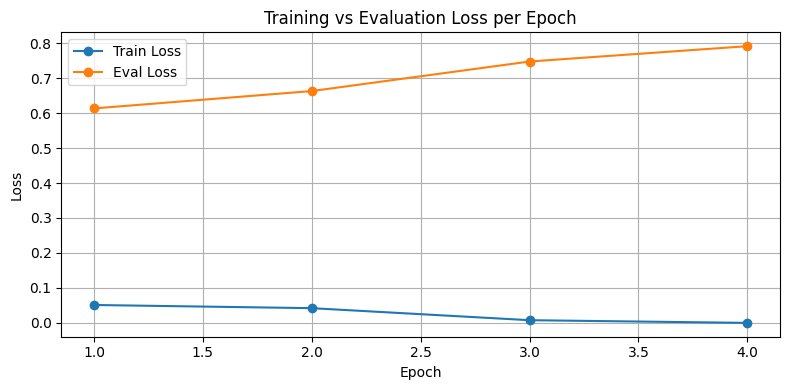

In [61]:
import matplotlib.pyplot as plt

def plot_train_eval_loss(csv_path):
    """
    Reads a CSV file and plots train vs eval loss per epoch.

    Parameters:
        csv_path (str): Path to the CSV file containing 'epoch', 'loss', and 'eval_loss' columns.
    """
    df = pd.read_csv(csv_path)

    plt.figure(figsize=(8, 4))
    plt.plot(df["epoch"], df["loss"], marker='o', label="Train Loss")
    plt.plot(df["epoch"], df["eval_loss"], marker='o', label="Eval Loss")

    plt.title("Training vs Evaluation Loss per Epoch")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_train_eval_loss("sentiment_transfer_learning_transformer/checkpoint_metrics_summary.csv")

the accuracy must be above 90 percent in just 2 or 3 epochs.

<h2>Changing the Variables Manually!</h2>

In [54]:
!nvidia-smi

Sat May  3 03:06:18 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.94                 Driver Version: 560.94         CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   53C    P8              3W /   25W |       0MiB /   6144MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [64]:
training_args_var_improved = TrainingArguments(
    output_dir = "./sentiment_transfer_learning_transformer_improved/",
    logging_dir = './sentiment_transfer_learning_transformer_improved/logs',

    logging_strategy = 'epoch',
    evaluation_strategy = 'epoch',
    save_strategy = 'epoch',
    load_best_model_at_end = True,

    num_train_epochs = 10,
    per_device_train_batch_size = 8,
    per_device_eval_batch_size = 8,
    
    learning_rate = 1e-5,
    weight_decay = 0.01,
    lr_scheduler_type = "linear",
    warmup_steps = 50,

    seed = 42,
    report_to = "none",
)

PyTorch: setting up devices


In [65]:
trainer_improved = Trainer(
    model=model,
    args=training_args_var_improved,
    train_dataset=dataset_train,
    eval_dataset=dataset_test,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
    # callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]
)

trainer_improved.train()

The following columns in the training set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: review, __index_level_0__. If review, __index_level_0__ are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
c:\Users\niush\anaconda3\lib\site-packages\transformers\optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(
***** Running training *****
  Num examples = 800
  Num Epochs = 10
  Instantaneous batch size per device = 8
  Total train batch size (w. parallel, distributed & accumulation) = 8
  Gradient Accumulation steps = 1
  Total optimization steps = 1000
  Number of trainable parameters = 108311810


  0%|          | 0/1000 [00:00<?, ?it/s]

The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: review, __index_level_0__. If review, __index_level_0__ are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 200
  Batch size = 8


{'loss': 0.0, 'learning_rate': 9.473684210526315e-06, 'epoch': 1.0}


  0%|          | 0/25 [00:00<?, ?it/s]

...

Saving model checkpoint to ./sentiment_transfer_learning_transformer_improved/checkpoint-1000
Configuration saved in ./sentiment_transfer_learning_transformer_improved/checkpoint-1000\config.json


{'eval_loss': 0.7389393448829651, 'eval_accuracy': 0.93, 'eval_precision': 0.9468085106382979, 'eval_recall': 0.9081632653061225, 'eval_f1': 0.9270833333333334, 'eval_roc_auc': 0.9792416966786714, 'eval_runtime': 7.0179, 'eval_samples_per_second': 28.499, 'eval_steps_per_second': 3.562, 'epoch': 10.0}


Model weights saved in ./sentiment_transfer_learning_transformer_improved/checkpoint-1000\pytorch_model.bin
tokenizer config file saved in ./sentiment_transfer_learning_transformer_improved/checkpoint-1000\tokenizer_config.json
Special tokens file saved in ./sentiment_transfer_learning_transformer_improved/checkpoint-1000\special_tokens_map.json


Training completed. Do not forget to share your model on huggingface.co/models =)


Loading best model from ./sentiment_transfer_learning_transformer_improved/checkpoint-300 (score: 0.7043742537498474).


{'train_runtime': 2580.054, 'train_samples_per_second': 3.101, 'train_steps_per_second': 0.388, 'train_loss': 0.007925825435246224, 'epoch': 10.0}


TrainOutput(global_step=1000, training_loss=0.007925825435246224, metrics={'train_runtime': 2580.054, 'train_samples_per_second': 3.101, 'train_steps_per_second': 0.388, 'train_loss': 0.007925825435246224, 'epoch': 10.0})

In [67]:
# Saving The Best model
 
trainer_improved.save_model("best_model_bert_sentiment_improved")
tokenizer.save_pretrained("best_model_bert_sentiment_improved")

Saving model checkpoint to best_model_bert_sentiment_improved
Configuration saved in best_model_bert_sentiment_improved\config.json
Model weights saved in best_model_bert_sentiment_improved\pytorch_model.bin
tokenizer config file saved in best_model_bert_sentiment_improved\tokenizer_config.json
Special tokens file saved in best_model_bert_sentiment_improved\special_tokens_map.json
tokenizer config file saved in best_model_bert_sentiment_improved\tokenizer_config.json
Special tokens file saved in best_model_bert_sentiment_improved\special_tokens_map.json


('best_model_bert_sentiment_improved\\tokenizer_config.json',
 'best_model_bert_sentiment_improved\\special_tokens_map.json',
 'best_model_bert_sentiment_improved\\vocab.txt',
 'best_model_bert_sentiment_improved\\added_tokens.json',
 'best_model_bert_sentiment_improved\\tokenizer.json')

In [68]:
df_improved = extract_checkpoint_metrics(base_dir="sentiment_transfer_learning_transformer_improved", output_file="checkpoint_metrics_summary_improved.csv")

Done! Metrics saved to: sentiment_transfer_learning_transformer_improved\checkpoint_metrics_summary_improved.csv


In [69]:
df_improved

,checkpoint,epoch,step,loss,eval_accuracy,eval_f1,eval_loss,eval_precision,eval_recall,eval_roc_auc,eval_runtime
0,checkpoint-100,1.0,100,0.0000,0.930,0.927083,0.884364,0.946809,0.908163,0.970688,7.4232
1,checkpoint-1000,10.0,1000,0.0000,0.930,0.927083,0.738939,0.946809,0.908163,0.979242,7.0179
2,checkpoint-200,2.0,200,0.0334,0.930,0.926316,0.808202,0.956522,0.897959,0.971589,6.9289
3,checkpoint-300,3.0,300,0.0167,0.930,0.927835,0.704374,0.937500,0.918367,0.975440,6.7717
4,checkpoint-400,4.0,400,0.0102,0.920,0.918367,0.734448,0.918367,0.918367,0.975890,6.8681
5,checkpoint-500,5.0,500,0.0000,0.915,0.913706,0.748440,0.909091,0.918367,0.975840,6.7318
6,checkpoint-600,6.0,600,0.0111,0.930,0.926316,0.832469,0.956522,0.897959,0.979242,6.7292
7,checkpoint-700,7.0,700,0.0078,0.930,0.927835,0.720854,0.937500,0.918367,0.977741,6.7157
8,checkpoint-800,8.0,800,0.0001,0.935,0.933333,0.710412,0.938144,0.928571,0.977641,6.7335
9,checkpoint-900,9.0,900,0.0000,0.930,0.927083,0.738305,0.946809,0.908163,0.979242,6.7353


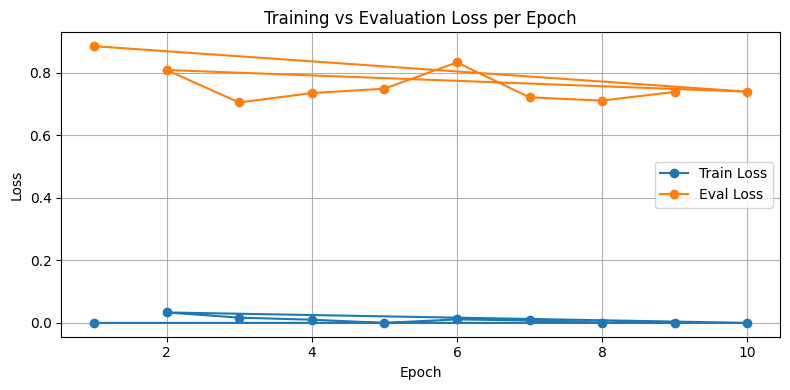

In [70]:
plot_train_eval_loss("sentiment_transfer_learning_transformer_improved/checkpoint_metrics_summary_improved.csv")

<h2>Changing The Variables with Optuna!</h2>

In [71]:
def model_init():
    return AutoModelForSequenceClassification.from_pretrained("bert-base-cased", num_labels=2)


In [72]:
# Define basic training arguments (no model saving/logging to avoid clutter)
training_args_hyperparam_tune = TrainingArguments(
    output_dir="./sentiment_transfer_learning_transformer_hyperparam_tune/",
    evaluation_strategy="epoch",         # Evaluate at the end of each epoch
    save_strategy="no",                  # Don't save checkpoints during tuning
    logging_strategy="epoch",           # Log metrics per epoch
    report_to="none",                   # Disable W&B or other integrations
    disable_tqdm=True,                  # Clean output (optional)
    load_best_model_at_end=False        # Not needed for hyperparameter search
)

PyTorch: setting up devices


In [73]:
# Create a Trainer object (note: model is created via model_init)
trainer_hyperparam_tune = Trainer(
    model_init=model_init,              # Function to reinitialize model for each trial
    args=training_args_hyperparam_tune,
    train_dataset=dataset_train,
    eval_dataset=dataset_test,
    compute_metrics=compute_metrics     # Your custom metrics (e.g. F1, accuracy)
)

c:\Users\niush\anaconda3\lib\site-packages\huggingface_hub\file_download.py:896: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
loading configuration file config.json from cache at C:\Users\niush/.cache\huggingface\hub\models--bert-base-cased\snapshots\cd5ef92a9fb2f889e972770a36d4ed042daf221e\config.json
Model config BertConfig {
  "_name_or_path": "bert-base-cased",
  "architectures": [
    "BertForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "classifier_dropout": null,
  "gradient_checkpointing": false,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_ty

In [74]:
# Perform hyperparameter search using Optuna
best_run_hyperparam_tune = trainer_hyperparam_tune.hyperparameter_search(
    direction="maximize",               # Optimize for higher F1 score
    backend="optuna",                   # Use Optuna as the optimization engine
    n_trials=10,                        # Number of different combinations to test
    hp_space=lambda trial: {
        "learning_rate": trial.suggest_float("learning_rate", 1e-5, 5e-5, log=True),
        "num_train_epochs": trial.suggest_int("num_train_epochs", 2, 5),
        "per_device_train_batch_size": trial.suggest_categorical("per_device_train_batch_size", [4, 8]),
        "weight_decay": trial.suggest_float("weight_decay", 0.0, 0.3),
    }
)

# Print the best set of hyperparameters found
print("Best run:")
print(best_run_hyperparam_tune)


[I 2025-05-03 04:11:01,548] A new study created in memory with name: no-name-c582dae2-af11-4684-a5fa-5ce65421e509
Trial: {'learning_rate': 3.535744738544033e-05, 'num_train_epochs': 2, 'per_device_train_batch_size': 4, 'weight_decay': 0.2711711313908575}
loading configuration file config.json from cache at C:\Users\niush/.cache\huggingface\hub\models--bert-base-cased\snapshots\cd5ef92a9fb2f889e972770a36d4ed042daf221e\config.json
Model config BertConfig {
  "_name_or_path": "bert-base-cased",
  "architectures": [
    "BertForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "classifier_dropout": null,
  "gradient_checkpointing": false,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "transformer

{'loss': 0.4587, 'learning_rate': 1.7678723692720167e-05, 'epoch': 1.0}
{'eval_loss': 0.41200315952301025, 'eval_accuracy': 0.9, 'eval_precision': 0.875, 'eval_recall': 0.9285714285714286, 'eval_f1': 0.900990099009901, 'eval_roc_auc': 0.9379751900760305, 'eval_runtime': 3.1376, 'eval_samples_per_second': 63.744, 'eval_steps_per_second': 7.968, 'epoch': 1.0}


The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: review, __index_level_0__. If review, __index_level_0__ are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 200
  Batch size = 8


{'loss': 0.1776, 'learning_rate': 0.0, 'epoch': 2.0}




Training completed. Do not forget to share your model on huggingface.co/models =)


[I 2025-05-03 04:20:25,888] Trial 0 finished with value: 4.773364718227716 and parameters: {'learning_rate': 3.535744738544033e-05, 'num_train_epochs': 2, 'per_device_train_batch_size': 4, 'weight_decay': 0.2711711313908575}. Best is trial 0 with value: 4.773364718227716.
Trial: {'learning_rate': 3.8963967848382004e-05, 'num_train_epochs': 5, 'per_device_train_batch_size': 8, 'weight_decay': 0.10678105060622052}


...

{'eval_loss': 0.2555386424064636, 'eval_accuracy': 0.925, 'eval_precision': 0.9278350515463918, 'eval_recall': 0.9183673469387755, 'eval_f1': 0.923076923076923, 'eval_roc_auc': 0.963985594237695, 'eval_runtime': 7.2725, 'eval_samples_per_second': 27.501, 'eval_steps_per_second': 3.438, 'epoch': 1.0}


c:\Users\niush\anaconda3\lib\site-packages\huggingface_hub\file_download.py:896: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
loading configuration file config.json from cache at C:\Users\niush/.cache\huggingface\hub\models--bert-base-cased\snapshots\cd5ef92a9fb2f889e972770a36d4ed042daf221e\config.json
Model config BertConfig {
  "_name_or_path": "bert-base-cased",
  "architectures": [
    "BertForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "classifier_dropout": null,
  "gradient_checkpointing": false,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_ty

{'loss': 0.4581, 'learning_rate': 1.719913117698258e-05, 'epoch': 1.0}


[I 2025-05-03 05:21:20,249] Trial 9 pruned. 


{'eval_loss': 0.24525555968284607, 'eval_accuracy': 0.925, 'eval_precision': 0.946236559139785, 'eval_recall': 0.8979591836734694, 'eval_f1': 0.9214659685863874, 'eval_roc_auc': 0.9653861544617847, 'eval_runtime': 8.1834, 'eval_samples_per_second': 24.44, 'eval_steps_per_second': 3.055, 'epoch': 1.0}
Best run:
BestRun(run_id='0', objective=4.773364718227716, hyperparameters={'learning_rate': 3.535744738544033e-05, 'num_train_epochs': 2, 'per_device_train_batch_size': 4, 'weight_decay': 0.2711711313908575})


In [79]:
# Read the full Optuna output log
with open("optuna_log_output.txt", "r", encoding="utf-8") as f:
    lines = f.readlines()

rows = []           # Each row = one epoch of one trial
trial_params = {}   # Holds current trial's fixed hyperparameters
trial_number = 0    # Trial counter

for line in lines:
    line = line.strip()

    # Detect the start of a new trial and extract hyperparameters
    if line.startswith("Trial: {"):
        trial_number += 1
        trial_params = {"trial_number": trial_number}
        params = eval(line.split("Trial: ")[1])
        trial_params.update(params)

    # Capture evaluation metrics for each epoch (if available)
    elif line.startswith("{'eval_loss'") or line.startswith("{\"eval_loss\""):
        try:
            metrics = eval(line)
            row = trial_params.copy()
            for k, v in metrics.items():
                if isinstance(v, float):
                    row[k] = round(v, 4)
                else:
                    row[k] = v
            rows.append(row)
        except:
            continue

# Convert to DataFrame and save
df_optuna = pd.DataFrame(rows)
df_optuna.to_csv("optuna_all_trials_all_epochs.csv", index=False)

print("All epochs saved to optuna_all_trials_all_epochs.csv")


All epochs saved to optuna_all_trials_all_epochs.csv


In [80]:
df_optuna

,trial_number,learning_rate,num_train_epochs,per_device_train_batch_size,weight_decay,eval_loss,eval_accuracy,eval_precision,eval_recall,eval_f1,eval_roc_auc,eval_runtime,eval_samples_per_second,eval_steps_per_second,epoch
0,1,0.000035,2,4,0.271171,0.4120,0.900,0.8750,0.9286,0.9010,0.9380,3.1376,63.744,7.968,1.0
1,2,0.000039,5,8,0.106781,0.2962,0.950,0.9681,0.9286,0.9479,0.9788,7.0651,28.308,3.538,2.0
2,2,0.000039,5,8,0.106781,0.3372,0.905,0.8835,0.9286,0.9055,0.9403,34.0520,5.873,0.734,1.0
3,2,0.000039,5,8,0.106781,0.3101,0.925,0.9368,0.9082,0.9223,0.9776,33.8045,5.916,0.740,2.0
4,2,0.000039,5,8,0.106781,0.3741,0.935,0.9474,0.9184,0.9326,0.9724,33.7928,5.918,0.740,3.0
5,2,0.000039,5,8,0.106781,0.4839,0.925,0.9278,0.9184,0.9231,0.9727,33.7848,5.920,0.740,4.0
6,3,0.000022,3,4,0.214134,0.4813,0.930,0.9375,0.9184,0.9278,0.9747,9.2792,21.554,2.694,5.0
7,3,0.000022,3,4,0.214134,0.2756,0.930,0.9468,0.9082,0.9271,0.9611,3.0538,65.492,8.187,1.0
8,3,0.000022,3,4,0.214134,0.3269,0.930,0.9565,0.8980,0.9263,0.9783,3.3021,60.568,7.571,2.0
9,4,0.000050,5,8,0.279752,0.3286,0.935,0.9570,0.9082,0.9319,0.9829,3.3320,60.024,7.503,3.0


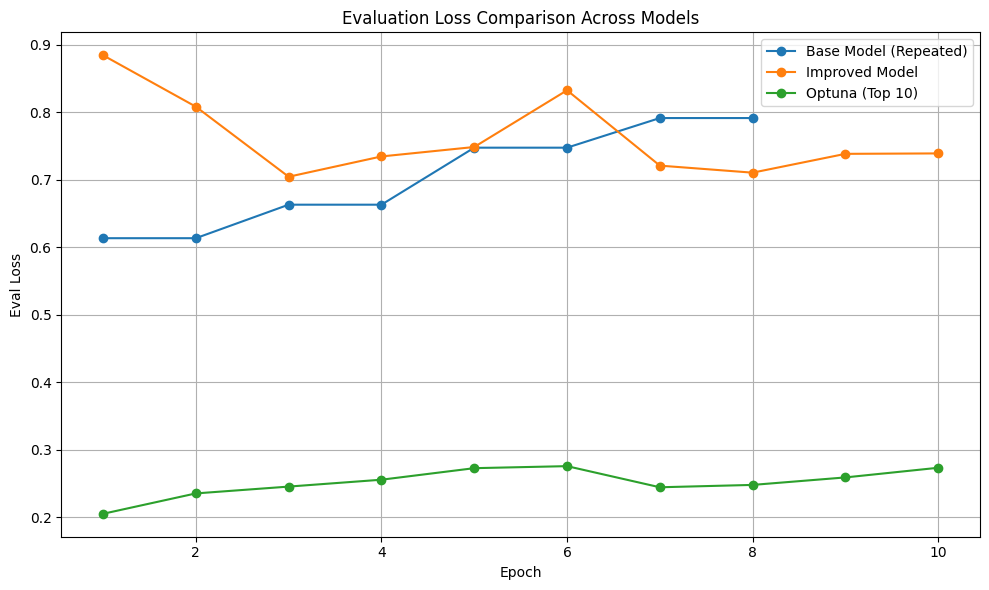

In [86]:
# Load all three CSVs
df_base = pd.read_csv("sentiment_transfer_learning_transformer/checkpoint_metrics_summary.csv")
df_improved = pd.read_csv("sentiment_transfer_learning_transformer_improved/checkpoint_metrics_summary_improved.csv")
df_optuna = pd.read_csv("sentiment_transfer_learning_transformer_hyperparam_tune/optuna_all_trials_all_epochs.csv")

# ------------------------
# Base model: repeat each eval_loss twice to reach 10 points
df_base_sorted = df_base.sort_values("epoch")
base_loss_doubled = df_base_sorted["eval_loss"].repeat(2).reset_index(drop=True)
epochs_base = list(range(1, len(base_loss_doubled) + 1))

# ------------------------
# Improved model: use as-is
df_improved_sorted = df_improved.sort_values("epoch")
epochs_improved = df_improved_sorted["epoch"]
loss_improved = df_improved_sorted["eval_loss"]

# ------------------------
# Optuna: pick 10 best eval_loss values across all trials
df_optuna_sorted = df_optuna.sort_values("eval_loss").head(10)
df_optuna_sorted = df_optuna_sorted.sort_values("epoch")  # sort by epoch for smoother curve
epochs_optuna = list(range(1, len(df_optuna_sorted) + 1))
loss_optuna = df_optuna_sorted["eval_loss"]

# ------------------------
# Plotting
plt.figure(figsize=(10, 6))

plt.plot(epochs_base, base_loss_doubled, marker='o', label="Base Model (Repeated)")
plt.plot(epochs_improved, loss_improved, marker='o', label="Improved Model")
plt.plot(epochs_optuna, loss_optuna, marker='o', label="Optuna (Top 10)")

plt.title("Evaluation Loss Comparison Across Models")
plt.xlabel("Epoch")
plt.ylabel("Eval Loss")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# Step 10: Make Predictions for Text Classification

In step 10, we will talk about how to make predictions using the Hugging Face transformer Trainer model.

Passing the tokenized `Dataset` to the `.predict` method, we get the predictions for the customized transfer learning sentiment model. We can see that the prediction results contain multiple pieces of information.
* `Num examples = 200` indicates that there are 200 reviews in the testing dataset.
* `Batch size = 4` means that 4 reviews are processed each time.
* Under `PredictionOutput`, `predictions` has the logits for each class. logit is the last layer of the neural network before softmax is applied. `label_ids` has the actual labels. Please note that it is not predicted labels although it is under the `PredictionOutput`. We need to calculate the predicted labels based on the logit values.
* Under `metrics` there is information about the testing predictions.
 * `test_loss` is the loss for the testing dataset.  
 * `test_accuracy` is the percentage of correct predictions.
 * `test_runtime` is the runtime for testing.
 * `test_samples_per_second` is the number of samples the model can process in one second.
 * `test_steps_per_second` is the number of steps the model can process in one second.


In [108]:
# Run predictions using the fine-tuned model
y_test_predict = trainer_hyperparam_tune.predict(dataset_test)

y_test_predict

The following columns in the test set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: review, __index_level_0__. If review, __index_level_0__ are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Prediction *****
  Num examples = 200
  Batch size = 8


PredictionOutput(predictions=array([[-2.1604018 ,  1.830906  ],
       [-2.2700777 ,  1.8400943 ],
       [-2.2391727 ,  1.9554585 ],
       [ 1.3721502 , -1.3700819 ],
       [ 1.1361887 , -1.1619025 ],
       [-2.407266  ,  1.9388683 ],
       [ 1.007642  , -1.0536374 ],
       [ 1.4199715 , -1.3783813 ],
       [-2.0942442 ,  1.7481089 ],
       [ 1.3480712 , -1.3903517 ],
       [-2.2798731 ,  1.9994271 ],
       [ 0.98099893, -1.1100652 ],
       [-0.77576333,  1.1260519 ],
       [-2.5000134 ,  2.0330675 ],
       [-2.3965197 ,  2.129101  ],
       [ 0.8080169 , -0.850708  ],
       [ 1.1049882 , -1.1110027 ],
       [-2.497545  ,  2.050708  ],
       [-2.4694383 ,  1.9792547 ],
       [ 1.4047484 , -1.4039563 ],
       [-2.2587724 ,  1.9711275 ],
       [ 0.9856377 , -1.0036421 ],
       [-2.4913738 ,  2.1409335 ],
       [ 1.3419591 , -1.2719984 ],
       [-1.6166834 ,  1.6044862 ],
       [-2.1368737 ,  1.8597226 ],
       [-2.3805034 ,  1.9519169 ],
       [ 1.294503  , -1.27

The predicted logits for the transfer learning text classification model can be extracted using `.predictions`.

We can see that the prediction has two columns. The first column is the predicted logit for label 0 and the second column is the predicted logit for label 1. logit values do not sum up to 1.

In [109]:
# Predicted logits
y_test_logits = y_test_predict.predictions

# First 5 predicted probabilities
y_test_logits[:5]

array([[-2.1604018,  1.830906 ],
       [-2.2700777,  1.8400943],
       [-2.2391727,  1.9554585],
       [ 1.3721502, -1.3700819],
       [ 1.1361887, -1.1619025]], dtype=float32)

To get the predicted probabilities, we need to apply softmax on the predicted logit values.

After applying softmax, we can see that the predicted probability for each review sums up to 1.

In [110]:
import torch.nn.functional as F
import torch

y_test_probabilities = F.softmax(torch.tensor(y_test_logits), dim=1).numpy()

y_test_probabilities[:5]

array([[0.01814038, 0.9818596 ],
       [0.01614017, 0.9838598 ],
       [0.01485238, 0.98514766],
       [0.9394731 , 0.06052686],
       [0.9087188 , 0.09128115]], dtype=float32)

To get the predicted labels, `argmax` is used to return the index of the maximum probability for each review, which corresponds to the labels of zeros and ones.

In [104]:
# Predicted labels
y_test_pred_labels = np.argmax(y_test_probabilities, axis=1)

# First 5 predicted probabilities
y_test_pred_labels[:5]

array([1, 1, 1, 0, 0], dtype=int64)

The actual labels can be extracted using `y_test_predict.label_ids`.

In [105]:
# Actual labels
y_test_actual_labels = y_test_predict.label_ids

# First 5 predicted probabilities
y_test_actual_labels[:5]

array([1, 1, 1, 0, 0], dtype=int64)

# Step 11: Model Performance Evaluation

In step 11, we will make the transfer learning text classification model performance evaluation.

`trainer.evaluate` is a quick way to get the loss and the accuracy of the testing dataset.

Applied on the best result of trainer_hyperparam_tune part

In [111]:
# Trainer evaluate
trainer_hyperparam_tune.evaluate(dataset_test)

The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: review, __index_level_0__. If review, __index_level_0__ are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 200
  Batch size = 8


{'eval_loss': 0.24525555968284607, 'eval_accuracy': 0.925, 'eval_precision': 0.946236559139785, 'eval_recall': 0.8979591836734694, 'eval_f1': 0.9214659685863874, 'eval_roc_auc': 0.9653861544617847, 'eval_runtime': 15.0913, 'eval_samples_per_second': 13.253, 'eval_steps_per_second': 1.657, 'epoch': 1.0}


{'eval_loss': 0.24525555968284607,
 'eval_accuracy': 0.925,
 'eval_precision': 0.946236559139785,
 'eval_recall': 0.8979591836734694,
 'eval_f1': 0.9214659685863874,
 'eval_roc_auc': 0.9653861544617847,
 'eval_runtime': 15.0913,
 'eval_samples_per_second': 13.253,
 'eval_steps_per_second': 1.657,
 'epoch': 1.0}

To calculate more model performance metrics, we can use `evaluate.load` to load the metrics of interest.

But since we have already calculate them in compute_metrics, we don't need to do that again.

# Step 12: Save and Load Model

In step 12, we will talk about how to save the model and reload it for prediction.

`tokenizer.save_pretrained` saves the tokenizer information to the drive and `model.save_model` saves the model to the drive.

In [ ]:
# Save tokenizer
tokenizer.save_pretrained('./sentiment_transfer_learning_transformer/')

# Save model
trainer.save_model('./sentiment_transfer_learning_transformer/')

We can load the saved tokenizer later using `AutoTokenizer.from_pretrained()` and load the saved model using `AutoModelForSequenceClassification.from_pretrained()`.

In [ ]:
# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained("./sentiment_transfer_learning_transformer/")

# Load model
loaded_model = AutoModelForSequenceClassification.from_pretrained('./sentiment_transfer_learning_transformer/')

# References

* [Hugging Face documentation on fine-tuning a pretrained model](https://huggingface.co/docs/transformers/training)
* [Hugging Face notebook on fine-tuning a pretrained model](https://github.com/huggingface/notebooks/blob/main/transformers_doc/en/training.ipynb)
* [Hugging Face documentation on tokenizer](https://huggingface.co/transformers/v3.5.1/main_classes/tokenizer.html)
* [Deeplearning.AI transfer learning video from Andrew Ng](https://www.youtube.com/watch?v=yofjFQddwHE)
* [Hugging Face TensorFlow predictions and metrics video](https://youtu.be/nx10eh4CoOs)
* [Hugging Face documentation on prepare_tf_dataset()](https://github.com/huggingface/notebooks/blob/main/transformers_doc/en/training.ipynb)
* [Hugging Face documentation on transformers.Trainer](https://huggingface.co/docs/transformers/main/en/main_classes/trainer#transformers.Trainer)
* [Hugging Face documentation on Datasets](https://huggingface.co/docs/datasets/v1.7.0/index.html#:~:text=Datasets%20and%20evaluation%20metrics%20for,Natural%20Language%20Processing%20(NLP).)